[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/10_free_energy_landscapes.ipynb)

# 10 · Free Energy Landscapes: The Ramachandran Map of Alanine Dipeptide

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~50 min*

A single structure tells you little; what matters is **how often** a molecule visits each shape. Statistical
mechanics turns those visiting frequencies into **free energies**: $F(x) = -k_BT\ln P(x)$. In this notebook
we simulate alanine dipeptide, the standard test case for conformational sampling, measure its backbone
dihedral angles φ and ψ, and build its **free energy landscape** (Ramachandran map), a 1-D **potential of mean
force (PMF)**, and state populations with error bars from independent replicas.

**Learning objectives.** By the end of this notebook you will be able to:

- compute backbone dihedrals φ/ψ from a trajectory with MDTraj
- turn a histogram into a free energy surface and a 1-D potential of mean force
- define conformational states, compute populations and free energy differences with error bars
- recognize under-sampled regions and know when enhanced sampling is needed

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm', 'mdtraj'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. A short live simulation

Alanine dipeptide (Ace-Ala-NMe, 22 atoms) has two flexible backbone torsions: φ (C–N–Cα–C) and ψ (N–Cα–C–N).
To make it fast we use **implicit solvent** (the GB-OBC II model): water is represented as a continuous dielectric
rather than explicit molecules, so the system has only 22 atoms. This is a good approximation for this
teaching purpose; Notebook 12 discusses when it is not.

200 ps in 91 s, 400 frames


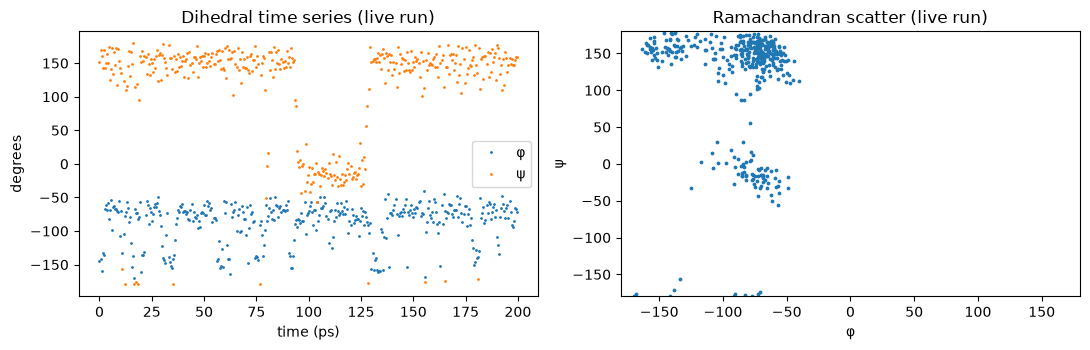

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmm
from openmm import app, unit
import mdtraj as md

LIVE_PS = 200                     # length of the live run; the precomputed data cover 4 x 10 ns
KT = 0.0083144626 * 300           # kJ/mol at 300 K

pdb = app.PDBFile(f"{DATA_DIR}/structures/alanine_dipeptide.pdb")
ff = app.ForceField("amber14-all.xml", "implicit/obc2.xml")
system = ff.createSystem(pdb.topology, nonbondedMethod=app.NoCutoff, constraints=app.HBonds)
integ = openmm.LangevinMiddleIntegrator(300 * unit.kelvin, 1 / unit.picosecond, 0.002 * unit.picoseconds)
integ.setRandomNumberSeed(7)
sim = app.Simulation(pdb.topology, system, integ, openmm.Platform.getPlatformByName("CPU"))
sim.context.setPositions(pdb.positions)
sim.minimizeEnergy()
sim.context.setVelocitiesToTemperature(300 * unit.kelvin, 7)

frames, t0 = [], time.time()
for _ in range(int(LIVE_PS / 0.5)):             # save every 0.5 ps
    sim.step(250)
    frames.append(sim.context.getState(getPositions=True).getPositions(asNumpy=True).value_in_unit(unit.nanometer))
live = md.Trajectory(np.array(frames), md.Topology.from_openmm(pdb.topology))
print(f"{LIVE_PS} ps in {time.time() - t0:.0f} s, {live.n_frames} frames")

_, phi = md.compute_phi(live); _, psi = md.compute_psi(live)
phi_live, psi_live = np.degrees(phi[:, 0]), np.degrees(psi[:, 0])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(live.n_frames) * 0.5, phi_live, ".", ms=2, label="φ"); ax[0].plot(np.arange(live.n_frames) * 0.5, psi_live, ".", ms=2, label="ψ")
ax[0].set(xlabel="time (ps)", ylabel="degrees", title="Dihedral time series (live run)"); ax[0].legend()
ax[1].scatter(phi_live, psi_live, s=3); ax[1].set(xlim=(-180, 180), ylim=(-180, 180), xlabel="φ", ylabel="ψ", title="Ramachandran scatter (live run)")
plt.tight_layout(); plt.show()

In a few hundred picoseconds the molecule hops between a few regions, but the scatter is sparse and some
regions are never visited. A free energy map needs many more samples. That is what the precomputed data are for.

## 2. The precomputed data: 4 independent 10 ns runs

The file holds φ/ψ every 1 ps from four replicas with different random seeds (same force field and settings
as above; see `data/README.md`). 40,000 frames in total.

In [3]:
df = pd.read_csv(f"{DATA_DIR}/trajectories/alanine_dipeptide_phi_psi.csv")
print(df.shape); print(df.groupby("replica").size().to_dict())
df.head()

(40000, 4)
{0: 10000, 1: 10000, 2: 10000, 3: 10000}


,replica,time_ps,phi_deg,psi_deg
0,0,1.0,-73.11,170.08
1,0,2.0,-55.78,146.37
2,0,3.0,-141.62,148.59
3,0,4.0,-151.27,175.03
4,0,5.0,-151.97,162.08


## 3. From histogram to free energy

Count how often each (φ, ψ) bin is visited, normalize to a probability $P$, and apply $F = -k_BT\ln P$, shifted so
the most populated bin has $F = 0$. Empty bins have infinite free energy in the estimate ("never seen" is not the
same as "impossible": it means "rarer than our sampling can detect").

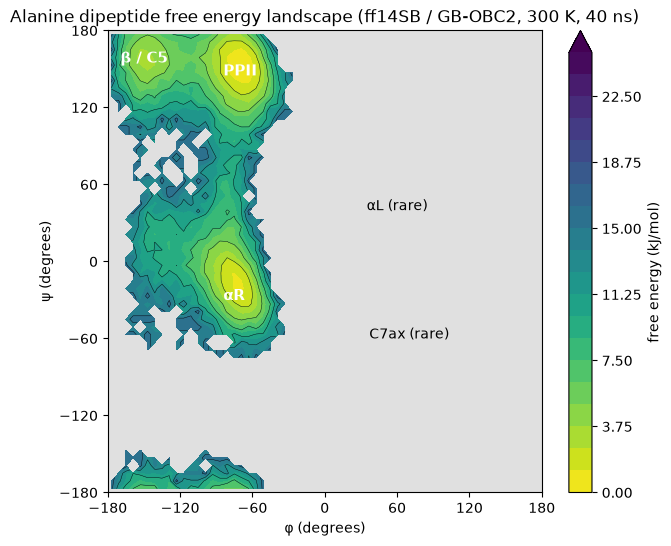

In [4]:
bins = np.linspace(-180, 180, 61)                # 6-degree bins
H, xe, ye = np.histogram2d(df.phi_deg, df.psi_deg, bins=[bins, bins])
P = H / H.sum()
with np.errstate(divide="ignore"):
    Fe = -KT * np.log(P)
Fe -= np.nanmin(Fe)

fig, ax = plt.subplots(figsize=(7, 6))
xc = 0.5 * (xe[1:] + xe[:-1])
cs = ax.contourf(xc, xc, Fe.T, levels=np.arange(0, 25.1, 1.25), cmap="viridis_r", extend="max")
ax.contour(xc, xc, Fe.T, levels=np.arange(0, 25.1, 2.5), colors="k", linewidths=0.3)
ax.set_facecolor("0.88")                         # grey = never visited in 40 ns
for name, (x, y) in {"β / C5": (-150, 155), "PPII": (-70, 145), "αR": (-75, -30)}.items():
    ax.annotate(name, (x, y), color="white", fontsize=11, fontweight="bold", ha="center")
for name, (x, y) in {"αL (rare)": (60, 40), "C7ax (rare)": (70, -60)}.items():
    ax.annotate(name, (x, y), color="black", fontsize=10, ha="center")
fig.colorbar(cs, label="free energy (kJ/mol)")
ax.set(xlabel="φ (degrees)", ylabel="ψ (degrees)", title="Alanine dipeptide free energy landscape (ff14SB / GB-OBC2, 300 K, 40 ns)",
       xticks=range(-180, 181, 60), yticks=range(-180, 181, 60))
os.makedirs("output", exist_ok=True)
plt.savefig("output/ramachandran_free_energy.png", dpi=150, bbox_inches="tight"); plt.show()

The map shows the familiar Ramachandran basins: the extended **β / PPII** region (upper left) and the right-handed
helix **αR** (lower left). Grey means "never visited". The left-handed **αL** and **C7ax** regions (φ > 0) are real
minima, but the barrier to reach them is high, so in 40 ns the molecule went there only a few times (counted in
Section 5) and they barely show up in the histogram. The contour
lines are spaced 2.5 kJ/mol (≈ 1 $k_BT$) apart. Every 5.7 kJ/mol of free energy is a factor of 10 in probability at 300 K.

## 4. A 1-D potential of mean force along φ

A PMF is the free energy along one coordinate, averaged (integrated) over everything else. Along φ it shows the
barrier separating φ < 0 from φ > 0.

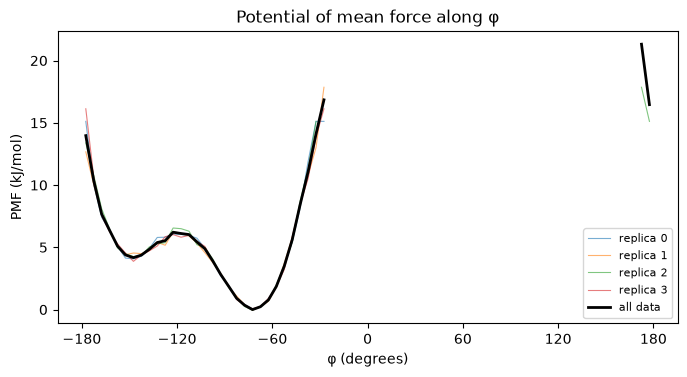

PMF bins never visited: 39 of 72
no frame between φ = -10 and 50 degrees: the PMF there is higher than about kT ln N = 26 kJ/mol


In [5]:
b1 = np.linspace(-180, 180, 73)
xc1 = 0.5 * (b1[1:] + b1[:-1])
pmfs = []
for rep, g in df.groupby("replica"):
    h, _ = np.histogram(g.phi_deg, bins=b1)
    with np.errstate(divide="ignore"):
        pmfs.append(-KT * np.log(h / h.sum()))
pmfs = np.array(pmfs)
h_all, _ = np.histogram(df.phi_deg, bins=b1)
with np.errstate(divide="ignore"):
    pmf = -KT * np.log(h_all / h_all.sum())
shift = np.nanmin(pmf[np.isfinite(pmf)])
pmf -= shift; pmfs -= shift

plt.figure(figsize=(8, 3.8))
for i, p in enumerate(pmfs):
    plt.plot(xc1, p, lw=0.8, alpha=0.6, label=f"replica {i}")
plt.plot(xc1, pmf, "k-", lw=2, label="all data")
plt.xlabel("φ (degrees)"); plt.ylabel("PMF (kJ/mol)"); plt.xticks(range(-180, 181, 60)); plt.legend(fontsize=8)
plt.title("Potential of mean force along φ"); plt.show()

finite = np.isfinite(pmf)
barrier_region = finite & (xc1 > -10) & (xc1 < 50)
print("PMF bins never visited:", int((~finite).sum()), "of", len(pmf))
if barrier_region.any():
    print(f"highest sampled PMF between φ = -10 and 50 degrees: {pmf[barrier_region].max():.1f} kJ/mol")
else:
    lower = -KT * np.log(1 / h_all.sum())
    print(f"no frame between φ = -10 and 50 degrees: the PMF there is higher than about kT ln N = {lower:.0f} kJ/mol")

Where replicas disagree, or where bins are empty, the estimate is limited by sampling, not by the force field.
Barrier tops are the least sampled places, so plain MD measures basins well and barriers poorly. **Enhanced
sampling** methods (umbrella sampling, metadynamics, replica exchange) exist precisely to fill in those regions.

## 5. States, populations, and free energy differences

Define states as regions of the map and count. With independent replicas we get an honest error bar (standard
error of the mean over replicas).

In [6]:
def state(phi, psi):
    s = np.full(len(phi), "other", dtype=object)
    s[(phi < 0) & ((psi > 100) | (psi < -150))] = "β/PPII"
    s[(phi < 0) & (psi > -120) & (psi <= 100)] = "αR"
    s[phi >= 0] = "αL/C7ax"
    return s

df["state"] = state(df.phi_deg.values, df.psi_deg.values)
pop = df.groupby(["replica", "state"]).size().unstack(fill_value=0)
pop = pop.div(pop.sum(axis=1), axis=0)
summary = pd.DataFrame({"population (mean)": pop.mean(), "SEM over replicas": pop.std(ddof=1) / np.sqrt(len(pop))})
ref = summary.loc["β/PPII", "population (mean)"]
summary["ΔF vs β/PPII (kJ/mol)"] = -KT * np.log(summary["population (mean)"] / ref)
display(pop.round(3))
summary.round(4)

state,other,αL/C7ax,αR,β/PPII
replica,,,,
0,0.000,0.0,0.352,0.648
1,0.000,0.0,0.379,0.620
2,0.001,0.0,0.415,0.584
3,0.000,0.0,0.363,0.637


,population (mean),SEM over replicas,ΔF vs β/PPII (kJ/mol)
state,,,
other,0.0003,0.0001,19.0495
αL/C7ax,0.0002,0.0001,20.0609
αR,0.3774,0.0137,1.2469
β/PPII,0.6221,0.0139,-0.0000


In [7]:
# How often does the molecule switch between alpha-R and beta/PPII? (count transitions, ignoring "other" frames)
trans = {}
for rep, g in df.groupby("replica"):
    s = g.state[g.state.isin(["β/PPII", "αR"])].values
    trans[rep] = int((s[1:] != s[:-1]).sum())
print("αR <-> β/PPII transitions per 10 ns:", trans)
into_pos = {rep: int(((g.phi_deg.values[1:] >= 0) & (g.phi_deg.values[:-1] < 0)).sum()) for rep, g in df.groupby("replica")}
print("transitions into φ > 0 per replica:", into_pos)

αR <-> β/PPII transitions per 10 ns: {0: 259, 1: 286, 2: 285, 3: 242}
transitions into φ > 0 per replica: {0: 1, 1: 2, 2: 4, 3: 1}


The fast αR ↔ β/PPII exchange happens many times per nanosecond, so those populations are well converged and the
replicas agree. Crossings to φ > 0 are rare, so the αL/C7ax population has a much larger *relative* error. This is
the general rule: **a free energy difference is only as good as the number of transitions you observed**.

**Force field note.** These numbers describe ff14SB with GB-OBC2 implicit water, not real alanine. Explicit water
and other force fields shift the αR/β balance, which is one reason force fields are validated against NMR data for
short peptides.

### ✏️ Exercise 1

Recompute the 2-D free energy map with **only one replica** and with **2-degree bins** instead of 6. What happens
to the number of empty bins and to the noise? What does this tell you about choosing bin sizes?

In [8]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
g = df[df.replica == 0]
for width in (6, 2):
    b = np.arange(-180, 181, width)
    h, _, _ = np.histogram2d(g.phi_deg, g.psi_deg, bins=[b, b])
    print(f"{width}-degree bins: {(h == 0).mean() * 100:.0f}% empty, median count in visited bins {np.median(h[h > 0]):.0f}")
```

</details>

### ✏️ Exercise 2

Compute the free energy difference between αR and β/PPII separately for each replica, then report the mean and
the standard error. Compare with the value in `summary`.

In [9]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
dF = -KT * np.log(pop["αR"] / pop["β/PPII"])
print(dF.round(2).to_dict())
print(f"mean {dF.mean():.2f} ± {dF.std(ddof=1) / np.sqrt(len(dF)):.2f} kJ/mol")
```

</details>

### ✏️ Exercise 3

How much data is enough? Using replica 0 only, compute the αR population from the first 1, 2, 5, and 10 ns. Plot
it against simulation length.

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
g = df[df.replica == 0]
lengths = [1, 2, 5, 10]
p = [(g.state[g.time_ps <= L * 1000] == "αR").mean() for L in lengths]
plt.plot(lengths, p, "o-"); plt.xlabel("simulation length (ns)"); plt.ylabel("αR population"); plt.show()
```

</details>

## Key takeaways

- Free energy = −kT ln(probability): sampling statistics become thermodynamics.
- A PMF is the free energy along one coordinate; barriers are the hardest part to sample.
- Report populations and ΔF with error bars from independent replicas.
- Rare transitions limit accuracy; enhanced sampling methods address this.

**Next:** [11 · Protein–ligand MD: EGFR with erlotinib](11_protein_ligand_md.ipynb).